In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal

### Define State

In [2]:
class ApplicantState(TypedDict):

    applicant_name: str
    experience: int
    education: str
    technical_score: int

    application_status: str
    result: str

### Creating Nodes
Evaluate Application Node

In [3]:
def evaluate_applicant(state: ApplicantState):

    experience = state['experience']
    education = state['education']
    technical_score = state['technical_score']

    if experience >= 5 and technical_score >= 80:
        status = 'shortlist'

    elif experience >= 2 and technical_score >= 60:
        status = 'review'

    else:
        status = 'reject'

    return {
        'application_status': status
    }

Shortlist Applicant Node

In [4]:
def shortlist_applicant(state: ApplicantState):

    result = (
        f"{state['applicant_name']} has been shortlisted "
        "for the next interview round."
    )

    return {
        'result': result
    }

Send for manual review Node

In [5]:
def review_application(state: ApplicantState):

    result = (
        f"{state['applicant_name']}'s application has been "
        "sent for manual review."
    )

    return {
        'result': result
    }

Reject Applicant Node

In [6]:
def reject_application(state: ApplicantState):

    result = (
        f"{state['applicant_name']}'s application has been "
        "rejected because the minimum requirements were not met."
    )

    return {
        'result': result
    }

### Condition Checking Function

In [7]:
def check_application_status(
    state: ApplicantState
) -> Literal[
    "shortlist_applicant",
    "review_application",
    "reject_application"
]:

    if state['application_status'] == 'shortlist':
        return 'shortlist_applicant'

    elif state['application_status'] == 'review':
        return 'review_application'

    else:
        return 'reject_application'

### Define and Compile Graph

In [8]:
# Define Graph
graph = StateGraph(ApplicantState)

# Add Nodes
graph.add_node('evaluate_applicant', evaluate_applicant)
graph.add_node('shortlist_applicant', shortlist_applicant)
graph.add_node('review_application', review_application)
graph.add_node('reject_application', reject_application)

# add edges
graph.add_edge(START, 'evaluate_applicant')
# add conditional edges
graph.add_conditional_edges(
    'evaluate_applicant',
    check_application_status
)

graph.add_edge('shortlist_applicant', END)
graph.add_edge('review_application', END)
graph.add_edge('reject_application', END)

# compile graph
workflow = graph.compile()

### Execute Graph

In [9]:
# intitial input
initial_state = {
    'applicant_name': 'Ali',
    'experience': 6,
    'education': 'BS Computer Science',
    'technical_score': 88
}
# execute graph
result = workflow.invoke(initial_state)

result

{'applicant_name': 'Ali',
 'experience': 6,
 'education': 'BS Computer Science',
 'technical_score': 88,
 'application_status': 'shortlist',
 'result': 'Ali has been shortlisted for the next interview round.'}

### Visualize graph

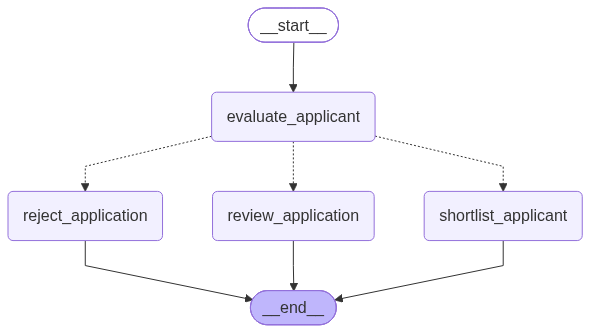

In [10]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())